# Numerical sequence-space perturbation

This notebook develops higher-order approximations through numerical differentiation of the smooth model from notebook 0. We first calculate how consumption responds to shocks of different sizes. We then introduce anticipated aggregate risk and interactions between successive shocks, use them to construct a generalized impulse response, and turn to general equilibrium.

We illustrate the paper's **certainty correspondence** (**Propositions 3 and 4**): the second- and third-order perturbation terms can be obtained from responses to successive unanticipated shocks (MIT shocks) and deterministic perturbations of expectations. We calculate size and history effects by differentiating MIT-shock responses, and risk effects using perturbed-expectations steady states and transitions. For general equilibrium, we use the **one-shot principle** (**Proposition 7**) to obtain each higher order from the lower-order solution and the same Jacobian used at first order.

This covers the main constructions in the paper's sections 3.1–3.4 and illustrates their numerical implementation from section 4. Notebook 2 uses analytical differentiation to calculate GE size and history effects, risk effects, and covariances; notebook 3 assembles the complete solution for simulation. A supplemental notebook A examines how well local approximations capture large fiscal shocks, following appendix D in the paper.

## 0. Setup

We use the same calibration as notebook 0, with assets $A=4$ and an impact income MPC of $0.2$. Steady-state quarterly GDP is one. We begin in partial equilibrium, holding the real interest rate and transfers fixed.

The household solver `hh.transition` takes an announced path of income deviations, `dZ`, and returns asset and consumption levels. Assets $A_t$ are measured after saving at date $t$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from smooth_sim.model import paper_household
from sequence_space.jacobian import income_jacobian_numerical

plt.rcParams["figure.figsize"] = (7, 3.5)
T = 300
rho_Z, rho_B = 0., 0.95
hh, ss = paper_household()
z = rho_Z**np.arange(T)
epsilon = 0.10
zero = hh.transition(ss, dZ=np.zeros(T)) # should be constant at SS, but slight numerical differences
print(f"Steady-state assets: {ss['A']:.6f}; consumption: {ss['C']:.6f}")


Steady-state assets: 4.000000; consumption: 0.830000


## 1. Shock size: numerical derivatives

We begin with a one-time proportional aggregate income shock, $\Delta Z_0=\nu$, holding interest rates, transfers, and future aggregate income fixed. Each household receives $\nu e_0\xi_0$, so the aggregate income injection is $\nu$.

Write $C(\nu)$ for the resulting consumption path. Its derivatives $C_1,C_2,C_3$ are also paths, with one entry per date; $C_2$ and $C_3$ give the second- and third-order size effects. **Proposition 2** gives the first-order certainty equivalence result, while **Propositions 3 and 4** establish the correspondence for the higher-order terms. We estimate them using the same centered-difference stencils as in notebook 0, with $h_1=10^{-4}$, $h_2=2\times10^{-4}$, and $h_3=10^{-3}$:
$$
C_1\approx\frac{C(h_1)-C(-h_1)}{2h_1},\qquad
C_2\approx\frac{C(h_2)-2C(0)+C(-h_2)}{h_2^2},
$$
$$
C_3\approx\frac{C(-3h_3)-8C(-2h_3)+13C(-h_3)-13C(h_3)+8C(2h_3)-C(3h_3)}{8h_3^3}.
$$
These are the step sizes recommended in the paper's section 4.4 ("Numerical differentiation"), chosen from a range over which the derivative estimates are stable as the step size varies.

The third-order approximation to the consumption response is $C(\nu)-C(0)\approx\nu C_1+\nu^2C_2/2+\nu^3C_3/6$.

In [2]:
def C(size):
    return hh.transition(ss, dZ=size*z)["C"]

h1, h2, h3 = 1e-4, 2e-4, 1e-3
C1 = (C(h1)-C(-h1))/(2*h1)
plus = hh.transition(ss, dZ=h2*z)
minus = hh.transition(ss, dZ=-h2*z)
C2 = (plus["C"]-2*zero["C"]+minus["C"])/h2**2
C3 = (C(-3*h3)-8*C(-2*h3)+13*C(-h3)-13*C(h3)+8*C(2*h3)-C(3*h3))/(8*h3**3)
print(f"Impact derivatives: {C1[0]:.5f}, {C2[0]:.5f}, {C3[0]:.5f}")


Impact derivatives: 0.20000, -0.96131, 4.11257


### Consumption after a 10%-of-GDP shock

Below we compare the nonlinear perfect-foresight response to a shock of size $\nu=0.10$ with its first-, second-, and third-order approximations over the first six quarters. All responses are divided by the initial shock size, so they measure consumption per dollar of additional income, as in notebook 0.

This corresponds to paper **Figure 1(a)**.

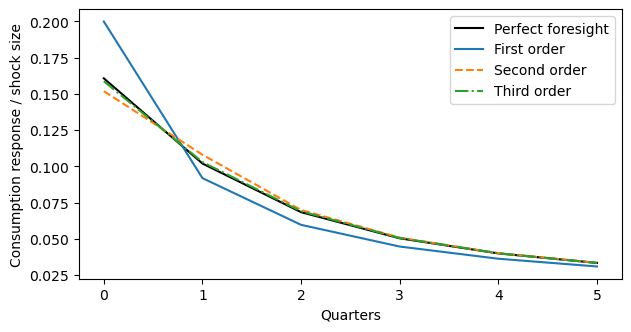

In [3]:
# Paper Figure 1(a).
positive = hh.transition(ss, dZ=epsilon*z)
plt.plot((positive["C"]-zero["C"])[:6]/epsilon, "k-", label="Perfect foresight")
plt.plot(C1[:6], "C0-", label="First order")
plt.plot((C1+epsilon*C2/2)[:6], "C1--", label="Second order")
plt.plot((C1+epsilon*C2/2+epsilon**2*C3/6)[:6], "C2-.", label="Third order")
plt.xlabel("Quarters"); plt.ylabel("Consumption response / shock size")
plt.legend();


We see that first order overstates the impact response and understates subsequent spending. The second-order correction captures much of this shift toward later spending, and third order is almost indistinguishable from the nonlinear benchmark. These derivatives are all evaluated at zero, yet they closely capture the response to a shock as large as 10% of quarterly GDP.

### Positive and negative shocks

We next vary the income shock from $-10\%$ to $10\%$ of quarterly GDP and look at impact consumption. The figure below corresponds to paper **Figure 2(a)**.

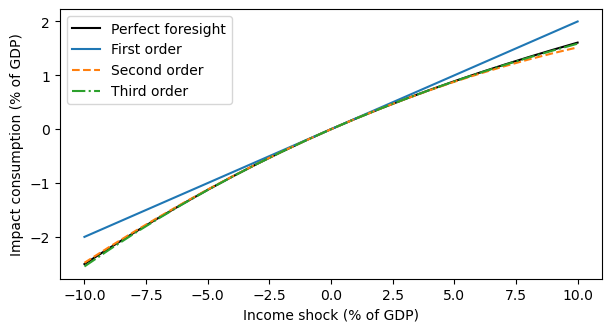

In [4]:
# Paper Figure 2(a).
sizes = np.linspace(-0.10, 0.10, 21)
consumption = np.array([hh.transition(ss, dZ=np.array([size, 0.]))["C"]-zero["C"][:2]
                        for size in sizes])
plt.plot(100*sizes, 100*consumption[:, 0], "k-", label="Perfect foresight")
plt.plot(100*sizes, 100*sizes*C1[0], "C0-", label="First order")
plt.plot(100*sizes, 100*(sizes*C1[0]+sizes**2*C2[0]/2), "C1--", label="Second order")
plt.plot(100*sizes, 100*(sizes*C1[0]+sizes**2*C2[0]/2+sizes**3*C3[0]/6), "C2-.", label="Third order")
plt.xlabel("Income shock (% of GDP)"); plt.ylabel("Impact consumption (% of GDP)")
plt.legend();

We see that the impact response is concave: an income loss reduces spending more than an equal gain raises it. Second and especially third order capture this asymmetry closely.

We next look at consumption at date 1 for the same range of shocks. This corresponds to paper **Figure 2(b)**.

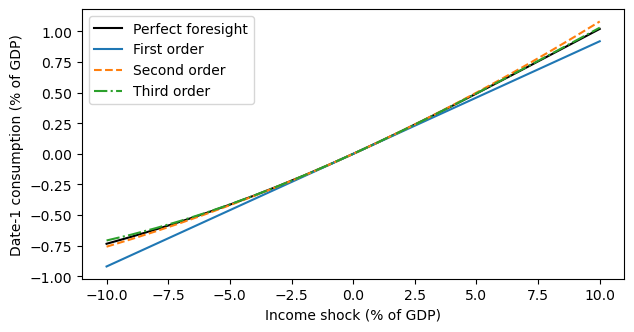

In [5]:
# Paper Figure 2(b).
plt.plot(100*sizes, 100*consumption[:, 1], "k-", label="Perfect foresight")
plt.plot(100*sizes, 100*sizes*C1[1], "C0-", label="First order")
plt.plot(100*sizes, 100*(sizes*C1[1]+sizes**2*C2[1]/2), "C1--", label="Second order")
plt.plot(100*sizes, 100*(sizes*C1[1]+sizes**2*C2[1]/2+sizes**3*C3[1]/6), "C2-.", label="Third order")
plt.xlabel("Income shock (% of GDP)"); plt.ylabel("Date-1 consumption (% of GDP)")
plt.legend();

At date 1, the response is instead convex, as the additional saving out of a large positive shock supports more spending later. Second and especially third order again closely track the nonlinear response.

Notebook A explores in more detail how these opposing nonlinear effects at dates 0 and 1 can largely offset each other.

## 2. Anticipated risk and the mean

We now let households anticipate iid aggregate income innovations symmetric around zero, with standard deviation $\sigma$. The **risky steady state** is the position reached when households anticipate this aggregate risk but realized innovations remain zero.

The paper's **second-order certainty correspondence** (**Proposition 3**) tells us how to obtain this risk effect from MIT-shock information: we perturb steady-state expectations in the direction of the second-order impact response, then differentiate the resulting steady state with respect to that perturbation.

In the household problem, expectations enter through the marginal value of future assets, which determines saving. Let $V_a$ denote this marginal value as a function of household state, and $V_{a,00}$ its second derivative with respect to an income innovation. A zero-mean innovation has no first-order effect on the expectation, but its variance contributes $\sigma^2 V_{a,00}/2$. We obtain $V_{a,00}$ from the date-0 marginal values returned by the same positive and negative transitions used above.

We then add a small shift $\delta V_{a,00}$ to future marginal value in every backward step and solve the steady state. Differentiating assets with respect to $\delta$ gives `A_risk`; multiplying by $\sigma^2/2$ gives the second-order shift in risky-steady-state assets.

In [6]:
Va00 = (plus["Va0"]-2*zero["Va0"]+minus["Va0"])/h2**2

delta = 1e-4
risk_plus = hh.steady_state(ss["r"], ss["Z"], ss["Tr"], Va_forcing=delta*Va00,
                           backward_tol=1e-11, forward_tol=1e-12)
risk_minus = hh.steady_state(ss["r"], ss["Z"], ss["Tr"], Va_forcing=-delta*Va00,
                            backward_tol=1e-11, forward_tol=1e-12)
A_risk = (risk_plus["A"]-risk_minus["A"])/(2*delta)

The **ergodic mean** also averages over the shocks that actually occur. Let $A_{2,t}$ be the second derivative of assets at date $t$ after a one-time income shock. Independence and zero means eliminate cross-date terms, leaving the sum of the second-order size effects over all shock ages:
$$
A_{rss}\approx A_{ss}+\frac{\sigma^2}{2}A_{risk},\qquad
E[A]\approx A_{rss}+\frac{\sigma^2}{2}\sum_{t\geq0} A_{2,t}.
$$
Below we plot both second-order approximations as aggregate risk increases. The risky-steady-state curve corresponds to paper **Figure 3(a)**.

Steady-state assets:  4.000000
Risky steady state:  4.011981
Ergodic mean assets: 4.018705


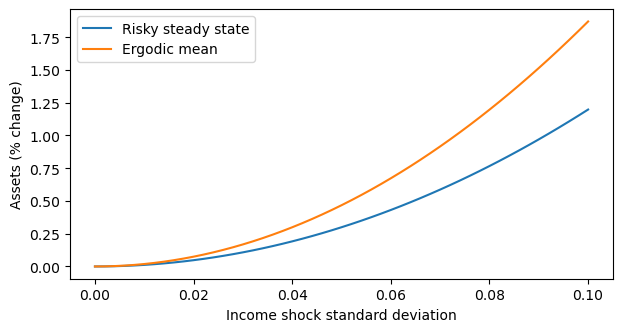

In [7]:
# Paper Figure 3(a): risky-steady-state curve; ergodic mean added here.
A2 = (plus["A"]-2*zero["A"]+minus["A"])/h2**2
sigma = 0.05
A_rss = ss["A"]+sigma**2*A_risk/2
A_mean = A_rss+sigma**2*A2.sum()/2
print(f"Steady-state assets:  {ss['A']:.6f}")
print(f"Risky steady state:  {A_rss:.6f}")
print(f"Ergodic mean assets: {A_mean:.6f}")

sigmas = np.linspace(0., 0.10, 51)
plt.plot(sigmas, 50*sigmas**2*A_risk/ss["A"], label="Risky steady state")
plt.plot(sigmas, 50*sigmas**2*(A_risk+A2.sum())/ss["A"], label="Ergodic mean")
plt.xlabel("Income shock standard deviation"); plt.ylabel("Assets (% change)")
plt.legend();

We see that anticipated risk raises assets, and averaging over realized shocks raises them further. At $\sigma=0.05$, the risky steady state has assets of about 4.012 and the ergodic mean about 4.019, compared with 4.000 without aggregate risk. For this calibration and level of aggregate risk, these are modest increases of about 0.3% and 0.5%, respectively.

The same calculation gives the change in the unconditional asset CDF. Below we compare the deterministic and risky steady states at $\sigma=0.05$, focusing on assets near the borrowing constraint as in paper **Figure 3(b)**.

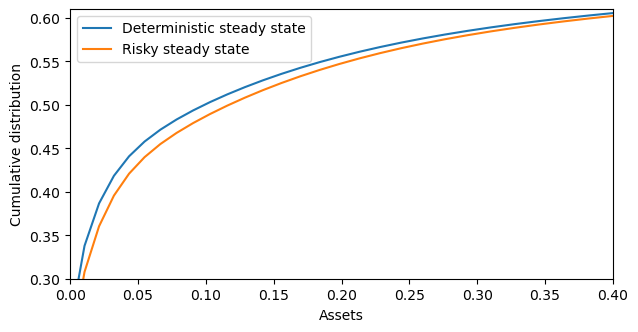

In [8]:
# Paper Figure 3(b).
F_risk = (risk_plus["F"]-risk_minus["F"])/(2*delta)
F_rss = ss["F"]+sigma**2*F_risk/2
plt.plot(hh.a_grid, hh.pi @ ss["F"], label="Deterministic steady state")
plt.plot(hh.a_grid, hh.pi @ F_rss, label="Risky steady state")
plt.xlim(0, 0.4); plt.ylim(0.3, 0.61)
plt.xlabel("Assets"); plt.ylabel("Cumulative distribution")
plt.legend();

The CDF shifts downward near the constraint: anticipated risk leads households to hold more assets and reduces the fraction at the borrowing constraint. This will also matter for how they respond to income shocks.

We have thus obtained the second-order effects of aggregate risk without solving the model under aggregate uncertainty. The required information came from MIT-shock responses and a perturbed-expectations steady state: this is the second-order certainty correspondence in practice.

## 3. Shock history: successive surprises

We next consider successive aggregate income shocks at dates $-1$ and $0$, allowing the response to the second shock to depend on the first. This is the history part of the second-order certainty correspondence in **Proposition 3**. To keep the second shock unanticipated, we carry the distribution from the first transition into a new transition. (Putting both shocks in a single transition calculation would instead let households anticipate the second shock when the first arrives.)

Let $C(x,y)$ denote the consumption path from date 0 onward, where $x$ is the earlier shock and $y$ the current one. Varying both shocks together gives the second derivative $C_{xx}+2C_{xy}+C_{yy}$. Subtracting the two size effects, $C_{xx}$ and $C_{yy}$, and dividing by two isolates the history effect $C_{xy}$. This "polarization identity" reuses the size effects we already calculated, so we only need the two joint shocks $(h,h)$ and $(-h,-h)$ rather than all four sign combinations in a direct mixed difference.

In [9]:
# calculate impulse response out to 10 periods after the second shock
def two_surprises(earlier, current):
    first = hh.transition(ss, dZ=np.array([earlier]), return_F=True)
    # F0 here is the distribution after the impact saving response to the first shock
    return hh.transition(ss, dZ=np.concatenate(([current], np.zeros(10))), F0=first["F"][1])["C"]

C_xx = C2[1:12] # size effect from earlier shock, starting one period later
C_yy = C2[:11]  # size effect from later shock
combined = (two_surprises(h2, h2) - 2*two_surprises(0., 0.)
            + two_surprises(-h2, -h2))/h2**2 # second derivative of varying both shocks together
C_xy = (combined - C_xx - C_yy)/2 # use polarization to extract history effect

We now consider two consecutive unexpected income shocks, $\epsilon_{-1}=\epsilon_0=0.10$, starting from the risky steady state with $\sigma=0.05$. Below we decompose the second-order terms in the consumption response from date 0 onward, as in paper **Figure 4(a)**. Contributions are measured as percentages of steady-state GDP.

The **current size effect** is the quadratic correction from the shock at date 0; the **previous size effect** is the corresponding correction from the shock at date $-1$, whose effects are still playing out. The **history effect** is the additional response due to the interaction between the two shocks.

The dashed line shows the risk effect, $r(A_{rss}-A_{ss})$, which raises consumption in the risky steady state through additional interest income. The four curves add up to the total second-order correction to consumption relative to the deterministic steady state; the first-order response is omitted.

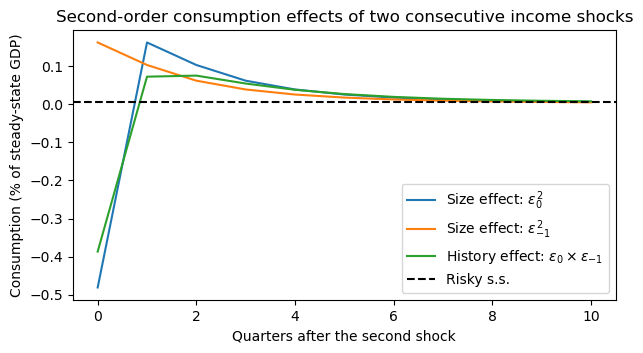

In [10]:
# Paper Figure 4(a).
C_risk = ss["r"]*(A_rss-ss["A"])
plt.plot(100*(epsilon**2*C_yy/2), label=r"Size effect: $\epsilon_0^2$")
plt.plot(100*(epsilon**2*C_xx/2), label=r"Size effect: $\epsilon_{-1}^2$")
plt.plot(100*(epsilon**2*C_xy), label=r"History effect: $\epsilon_0 \times \epsilon_{-1}$")
plt.axhline(100*C_risk, color="k", linestyle="--", label="Risky s.s.")
plt.title("Second-order consumption effects of two consecutive income shocks")
plt.xlabel("Quarters after the second shock"); plt.ylabel("Consumption (% of steady-state GDP)")
plt.legend();

The history effect is negative when the second shock arrives and positive afterward. The earlier positive shock has strengthened household balance sheets, reducing the additional consumption generated by the new shock on impact and shifting more spending into later quarters. Its impact contribution is comparable to the current shock's size effect, so simply adding two independent responses would miss an important part of the second-order effect.

### Third-order size and history effects

The third-order certainty correspondence in **Proposition 4** includes both mixed size–history effects involving two shock dates, with one shock entering quadratically, and an interaction involving three distinct dates. To separate these effects, we extend the restart calculation to three successive surprises.

The function below carries the distribution forward after each surprise and returns consumption from the last shock onward. We then apply the seven-point stencil along a chosen vector of shock sizes, such as $(1,1)$ for two equal shocks or $(1,0,1)$ for two shocks two quarters apart.

In [ ]:
# Shock entries are consecutive dates; zero entries leave a gap between surprises.
def consumption_surprises(shocks):
    F = ss["F"]
    for shock in shocks[:-1]:
        path = hh.transition(ss, dZ=np.array([shock]), F0=F, return_F=True)
        F = path["F"][1] # distribution after this period's saving, inherited by next date
    # Return dates 0-11 after the last shock; the extra date is used to align pair effects below.
    return hh.transition(ss, dZ=np.concatenate(([shocks[-1]], np.zeros(11))), F0=F)["C"]

# Third derivative with respect to a common scale multiplying all shock sizes.
def cubic(shocks):
    def C(scale):
        return consumption_surprises([scale*s for s in shocks])
    return (C(-3*h3)-8*C(-2*h3)+13*C(-h3)-13*C(h3)+8*C(2*h3)-C(3*h3))/(8*h3**3)


For two shocks, varying both together gives the third derivative $C_{xxx}+3C_{xxy}+3C_{xyy}+C_{yyy}$. As at second order, we subtract the cubic size effects to isolate the interaction. Dividing by three gives the sum $C_{xxy}+C_{xyy}$, which we call `C_pair1` for shocks one quarter apart and `C_pair2` for shocks two quarters apart. Each path is measured from the later shock.

In [ ]:
# Sums of mixed third derivatives for shocks one and two quarters apart.
C_pair1 = (cubic((1, 1))-C3[:12]-C3[1:13])/3
C_pair2 = (cubic((1, 0, 1))[:11]-C3[:11]-C3[2:13])/3

Now let $x,y,z$ denote shocks at dates $-2,-1,0$. Varying all three together gives the sum of their cubic size effects, plus three times the sum of the six mixed pair derivatives, plus $6C_{xyz}$. We collect these size effects in `C_size` and the mixed pair derivatives in `C_pairs`, aligning all paths at date 0. The pair at dates $-2,-1$ has already evolved for one quarter by then, so its response starts at `C_pair1[1:]`. Subtracting these size and pair terms and dividing by six isolates $C_{xyz}$.

In [12]:
C_size = C3[2:13]+C3[1:12]+C3[:11] # C_xxx + C_yyy + C_zzz, measured from date 0
C_pairs = C_pair1[1:]+C_pair1[:-1]+C_pair2 # pairs (x,y), (y,z), and (x,z)
combined = cubic((1, 1, 1))[:11] # third derivative of varying all three shocks together
C_xyz = (combined-C_size-3*C_pairs)/6 # use polarization to extract the three-date interaction


### Risk changes shock transmission

To calculate how anticipated risk changes shock transmission, we compare the first-order consumption responses to an income shock around the two perturbed steady states used above, keeping their expectation shifts in place throughout each transition. As before, $\delta$ scales the shift $\delta V_{a,00}$ in expected marginal value. Differentiating the first-order consumption response with respect to $\delta$ gives `C_RSS`, the RSS transmission derivative. For a shock of size $\epsilon$, multiplying this derivative by $\sigma^2\epsilon/2$ gives a third-order contribution: second order in risk and first order in shock size. This is the **risky-steady-state (RSS) transmission effect** in the paper's third-order certainty correspondence (**Proposition 4**).

Here, at fixed prices with iid aggregate income, today's shock does not change the future marginal-value correction for risk. There is therefore no additional "time-varying precautionary" effect; that channel will matter in GE in notebook 2.

In [13]:
# First-order consumption response to an income shock at a perturbed steady state.
def consumption_response(steady, expectation_shift):
    forcing = np.broadcast_to(expectation_shift, (T,)+Va00.shape)
    plus = hh.transition(steady, dZ=h1*z, Va_forcing=forcing)["C"]
    minus = hh.transition(steady, dZ=-h1*z, Va_forcing=forcing)["C"]
    return (plus-minus)/(2*h1)

# Differentiate this response with respect to the expectation-shift parameter delta.
C_RSS = (consumption_response(risk_plus, delta*Va00)
         -consumption_response(risk_minus, -delta*Va00))/(2*delta)


The earlier second-order plot decomposed the consumption effects of two consecutive shocks. We now plot the third-order contributions for three consecutive unexpected shocks at dates $-2,-1,0$, each of size $0.10$, again starting from the risky steady state with $\sigma=0.05$. As in the second-order plot, time is measured from the last shock, and the four curves sum to the correction at the order shown—here third order, with the first- and second-order terms omitted. Contributions are again measured as percentages of steady-state GDP. This corresponds to paper **Figure 4(b)**.

The **cubic size effects** collect the separate size effects of all three shocks. The **mixed size–history effects** collect interactions involving two shock dates, while the **three-date interaction** involves all three shocks together. The **risk effect** now shows how anticipated risk changes the response to the shocks. This differs from the constant risky-steady-state shift in the second-order plot: at third order, risk changes shock transmission, so its contribution varies over time.

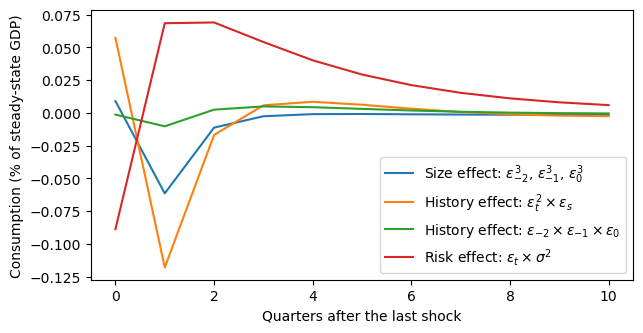

In [14]:
# Paper Figure 4(b).
plt.plot(100*epsilon**3*C_size/6, label=r"Size effect: $\epsilon_{-2}^3$, $\epsilon_{-1}^3$, $\epsilon_0^3$")
plt.plot(100*epsilon**3*C_pairs/2, label=r"History effect: $\epsilon_t^2 \times \epsilon_s$")
plt.plot(100*epsilon**3*C_xyz, label=r"History effect: $\epsilon_{-2} \times \epsilon_{-1} \times \epsilon_0$")
plt.plot(100*sigma**2*epsilon*(C_RSS[:11]+C_RSS[1:12]+C_RSS[2:13])/2, label=r"Risk effect: $\epsilon_t \times \sigma^2$")
plt.xlabel("Quarters after the last shock"); plt.ylabel("Consumption (% of steady-state GDP)")
plt.legend();

We see that mixed size–history effects matter at short horizons, while the interaction across three distinct dates is relatively small here. Anticipated risk lowers spending on impact but becomes the largest displayed contribution after the first few quarters, raising consumption through changes in saving policies and the pre-shock asset distribution.

### Generalized impulse responses

A generalized impulse response (GIRF) measures the revision to expected consumption when a shock is realized. In the special case where past shocks are zero, so that we're starting from the risky steady state, the impact formula in **Proposition 5** reduces to
$$
IRF_0^{(3)}(\nu,\sigma)
= C_{1,0}\nu+\frac12 C_{2,0}(\nu^2-\sigma^2)
+\frac16 C_{3,0}\nu^3+\frac12 C_{\sigma\sigma,0}\sigma^2\nu,
$$
where $C_{\sigma\sigma,0}$ is `C_RSS[0]` in this iid PE model. We already have all these derivatives. Below we reproduce paper **Figure 5(c)** at $\sigma=0.05$, comparing the second- and third-order GIRFs with the perfect-foresight response calculated earlier.

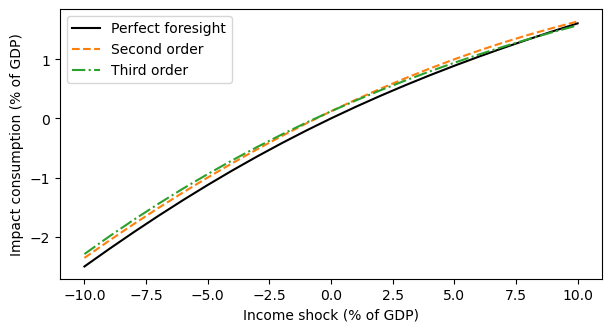

In [15]:
# Paper Figure 5(c).
girf2 = C1[0]*sizes+C2[0]*(sizes**2-sigma**2)/2
girf3 = girf2+C3[0]*sizes**3/6+C_RSS[0]*sigma**2*sizes/2

plt.plot(100*sizes, 100*consumption[:, 0], "k-", label="Perfect foresight")
plt.plot(100*sizes, 100*girf2, "C1--", label="Second order")
plt.plot(100*sizes, 100*girf3, "C2-.", label="Third order")
plt.xlabel("Income shock (% of GDP)"); plt.ylabel("Impact consumption (% of GDP)")
plt.legend();

The GIRFs lie above the perfect-foresight response near zero: with concave consumption, a zero innovation is better news than the average outcome anticipated beforehand, giving the positive correction $-C_{2,0}\sigma^2/2$. The third-order curve is flatter than the second-order curve near zero because anticipated risk lowers the impact MPC.

## 4. General equilibrium with the one-shot principle

We now return to the steady state without aggregate risk and consider a debt-financed proportional tax cut. Government debt rises by $\nu$ on impact and then returns gradually to steady state, $B_t-B_{ss}=\nu\rho_B^t$, with $\rho_B=0.95$. Taxes adjust to finance this path, while the real interest rate, government purchases, and lump-sum transfers remain fixed. With fixed government spending, output and consumption changes coincide, $\Delta Y_t=\Delta C_t$; we describe the GE results in terms of output.

In the **intertemporal Keynesian cross (IKC)**, spending generates income, so after-tax labor income $Z$ is now endogenous. We seek the income path that makes household saving equal government debt:
$$A(Z)-B=0.$$

Let $J_{ts}=\partial A_t/\partial Z_s$ be the household asset-income Jacobian, which we calculate using the fake-news algorithm with numerical differentiation. Writing $Z_1$ and $B_1$ for derivatives with respect to the debt innovation, first-order market clearing requires $JZ_1=B_1$. The code calls these paths `dZ` and `dB`.

In [16]:
J = income_jacobian_numerical(hh, ss, T)
dB = rho_B**np.arange(T)
dZ = np.linalg.solve(J, dB)

### Second order

The trial income path $Z_{ss}+\nu Z_1$ clears the asset market only to first order. Its second-order asset response must be offset by an income correction $Z_2$, since debt is linear in the innovation:
$$JZ_2=-\left.\frac{d^2}{d\nu^2}A(Z_{ss}+\nu Z_1)\right|_{\nu=0}.$$
We estimate this asset derivative using centered differences, then solve for $Z_2$ using the same Jacobian as at first order. This is the **one-shot principle** (**Proposition 7**): once the lower-order response is known, the next correction requires just one solve with the original linearized equilibrium system.

In [17]:
def assets(dZ_path):
    return hh.transition(ss, dZ=dZ_path)["A"]

d2A = (assets(h2*dZ)-2*zero["A"]+assets(-h2*dZ))/h2**2
d2Z = np.linalg.solve(J, -d2A)

### Third order

We now include the second-order correction in the trial income path and apply the same one-shot principle:
$$JZ_3=-\left.\frac{d^3}{d\nu^3}A\left(Z_{ss}+\nu Z_1+\frac{\nu^2}{2}Z_2\right)\right|_{\nu=0}.$$
This derivative captures both the cubic response along $Z_1$ and its interaction with the second-order correction $Z_2$. Numerically differentiating the asset response along this trial path includes both contributions, so we obtain $Z_3$ with one more solve using the same Jacobian.

In [18]:
def assets_second_order(size):
    return assets(size*dZ+size**2*d2Z/2)

d3A = (assets_second_order(-3*h3)-8*assets_second_order(-2*h3)
       +13*assets_second_order(-h3)-13*assets_second_order(h3)
       +8*assets_second_order(2*h3)-assets_second_order(3*h3))/(8*h3**3)
d3Z = np.linalg.solve(J, -d3A)

### A nonlinear benchmark

For comparison, we solve the fully nonlinear equilibrium for a debt shock of 10% of quarterly GDP. Starting from the first-order income response, we repeatedly adjust the income path until household saving matches government debt at every date. The reported residual checks that the remaining discrepancy is below $10^{-10}$ of quarterly GDP.

In [19]:
nu = 0.10
dZ_nonlinear = nu*dZ
for _ in range(30):
    nonlinear = hh.transition(ss, dZ=dZ_nonlinear)
    asset_error = nonlinear["A"]-ss["A"]-nu*dB
    if np.max(abs(asset_error)) < 1e-10:
        break
    dZ_nonlinear -= np.linalg.solve(J, asset_error)
assert np.max(abs(asset_error)) < 1e-10
print(f"Maximum asset-market residual: {np.max(abs(asset_error)):.2e}")


Maximum asset-market residual: 7.22e-11


The output response follows from the household budget:
$$\Delta Y_t=\Delta Z_t+(1+r)\Delta B_{t-1}-\Delta B_t.$$
Debt before the shock, $B_{-1}$, is unchanged, and the debt response contributes only at first order. The second and third output derivatives therefore equal $Z_2$ and $Z_3$.

Below we compare the resulting Taylor approximations with the nonlinear benchmark, dividing all responses by the initial debt shock. This corresponds to paper **Figure 1(b)**.

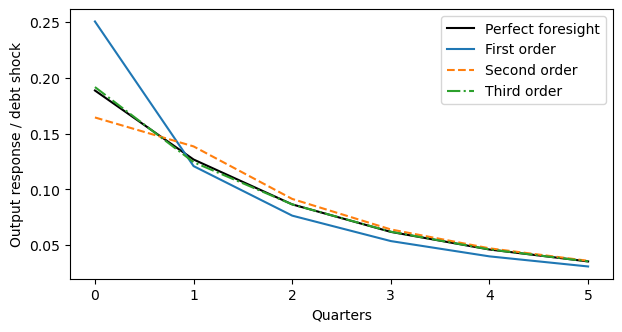

In [20]:
# Paper Figure 1(b).
dY = dZ+(1+ss["r"])*np.concatenate(([0.], dB[:-1]))-dB
plt.plot((nonlinear["C"]-zero["C"])[:6]/nu, "k-", label="Perfect foresight")
plt.plot(dY[:6], "C0-", label="First order")
plt.plot((dY+nu*d2Z/2)[:6], "C1--", label="Second order")
plt.plot((dY+nu*d2Z/2+nu**2*d3Z/6)[:6], "C2-.", label="Third order")
plt.xlabel("Quarters"); plt.ylabel("Output response / debt shock")
plt.legend();

We see that first order overstates impact output and second order understates it, while third order closely tracks the nonlinear equilibrium both on impact and in subsequent quarters—very similar to the PE comparison in Figure 1(a) above.

### Comparing quasi-Newton iterates and Taylor approximations

The paper states **Proposition 7** in a slightly different form from our calculation above. Starting from steady state, it repeatedly updates the income path using the nonlinear asset-market error and the steady-state Jacobian—the same quasi-Newton updates used in our nonlinear solver. Above, we instead calculated the income derivatives order by order and used them to construct Taylor approximations.

The two approaches agree through the corresponding order, although the quasi-Newton iterates can also contain higher-order terms. The first iterate is exactly $\nu Z_1$. The second and third differ from their Taylor approximations only at orders $\nu^3$ and $\nu^4$, respectively, so halving a small shock should reduce these differences by factors of about 8 and 16. We check this numerically below at $\nu=0.10$ and $\nu/2$, reporting maximum differences across dates in GDP units.

In [ ]:
def iterate_errors(size):
    path = taylor = size*dZ
    errors = []
    for correction in (size**2*d2Z/2, size**3*d3Z/6):
        path = path-np.linalg.solve(J, assets(path)-ss["A"]-size*dB)
        taylor = taylor+correction
        errors.append(np.max(abs(path-taylor)))
    return errors

for order, full, half in zip((2, 3), iterate_errors(nu), iterate_errors(nu/2)):
    print(f"Order {order}: max difference {full:.2e} -> {half:.2e}; falls by {full/half:.2f}x")


Order 2: max difference 1.79e-03 -> 2.11e-04; falls by 8.47x
Order 3: max difference 2.42e-04 -> 1.04e-05; falls by 23.22x


The check works well: halving the shock reduces the second-order difference by about 8 times and the third-order difference by about 23 times. This rapid decline supports the equivalence of our derivative-based implementation and the paper's iterative formulation through the relevant order, with only higher-order differences remaining in each case.

### Checking the first-order condition for Proposition 1

First-order determinacy and existence are prerequisites for the paper's higher-order analysis. **Assumption 1** gives the root and rank conditions underlying **Proposition 1**, and appendix A.2 ("Sequence-space form of assumption 1") shows that they are equivalent to invertibility of the infinite-dimensional sequence-space Jacobian. Together with smoothness, they give local existence and uniqueness of the nonlinear solution.

In partial equilibrium, the household problem already determines policies and the asset distribution given income and the initial distribution. The nontrivial question arises in general equilibrium, where income must itself be determined by asset-market clearing. Since we have already solved the household equations, the remaining condition is invertibility of the asset-income Jacobian $J$.

To check invertibility of the infinite-dimensional Jacobian, we use the SVD test recommended in section 3.3 of [*Determinacy and Large-Scale Solutions in the Sequence Space*](https://mrognlie.github.io/papers/determinacy_sequence_space.pdf): inspect singular values of finite truncations of $J$. The paper offers this as a practical, somewhat less precise alternative to the winding number test (which requires slightly more setup). A smallest singular value tending to zero would mean that sizable income changes can have vanishingly small effects on asset demand. Below we inspect the two smallest values and their ratio as we increase the truncation horizon, using blocks of the Jacobian already calculated above.

In [21]:
print(f"{'Horizon':>8} {'Smallest':>12} {'Next-smallest':>15} {'Ratio':>10}")
for horizon in (100, 200, T):
    s = np.linalg.svd(J[:horizon, :horizon], compute_uv=False)
    print(f"{horizon:8d} {s[-1]:12.6f} {s[-2]:15.6f} {s[-1]/s[-2]:10.6f}")

 Horizon     Smallest   Next-smallest      Ratio
     100     0.463685        0.463841   0.999662
     200     0.463645        0.463685   0.999915
     300     0.463638        0.463656   0.999962


The smallest singular value settles near 0.464 as the horizon increases, and is almost the same as the next-smallest. Neither is approaching zero. This provides numerical support for the first-order invertibility condition which, together with the model's smoothness, gives local existence and uniqueness under Proposition 1.

## Looking ahead

Finite differences have let us calculate size, history, and risk effects, and the one-shot principle carries the same approach into general equilibrium. The cost grows as we calculate more history effects, since each requires further nonlinear transitions. Notebook 2 turns to analytical differentiation, starting by checking agreement with the numerical calculations developed here.